In [8]:
import os, sys
import h5py
import numpy as np
import pandas as pd
import cv2
import torch
import time
from matplotlib import pyplot as plt

## Experiment Parameters

In [9]:
is_local = True # todo

if is_local:
    sys.path.append(r'C:/Users/w37262do/Documents/git/IR_preprocessing')
else:
    sys.path.append(r'/mnt/iusers01/eee01/w37262do/scratch/IR_preprocessing')
from src.preprocessing_tk import *

# Preprocessing protocol
protocol_name = sys.argv[1] if not is_local else 'pcasmooth'
protocol_args = sys.argv[2:] if not is_local else ['10',]

## Import Data Sheets

In [16]:
master_nocl = pd.read_excel(rf'D:/datasets/qcl2026_raw/master_sheet.xlsx' if is_local else r'./qcl2026_processed/master_sheet.xlsx')
master_nocl = master_nocl.iloc[np.where(master_nocl['annotated_pixels'].to_numpy() > 0)]

master_aus = pd.read_excel(rf'F:/datasets/aus_qcl2026_raw/master_sheet.xlsx' if is_local else r'./aus_qcl2026_processed/master_sheet.xlsx')
master_aus = master_aus.iloc[np.where(master_aus['annotated_pixels'].to_numpy() > 0)]

## Define Preprocessing Protocol

In [17]:
preprocessing_tk = get_processing_tk_from_name(protocol_name,protocol_args)

## Do Preprocessing & Saving Loop

In [18]:
save_base = r'G:\test_dir' if is_local else r'./'
raw_wavenumbers = np.load(r'D:/datasets/qcl2026_raw/wavenumbers.npy' if is_local else r'./wavenumbers.npy')
loop_start_time = time.time()
core_processing_times = []

In [19]:
print(f"Processing ...")
for didx,dset in enumerate([master_nocl, master_aus]):
    for cidx in range(len(dset)):

        # Get core name
        corename = dset['hdf5_filepath'].iloc[cidx].split('/')[-1].split('.')[0]
        print(f"DATASET {didx+1}/2 | CORE {cidx+1}/{len(dset)} = {corename}",end="")

        # open hdf5 file, get raw ir
        if is_local:
            hdf5_file = h5py.File(dset['hdf5_filepath'].iloc[cidx], 'r')
            mask = cv2.imread(dset['mask_filepath'].iloc[cidx])[:,:,0] / 255.0
        else:
            hdf5_file = h5py.File(dset['hdf5_filepath'].iloc[cidx].replace('D:/datasets/','/mnt/eps01-rds/GardnerLab/').replace('F:/datasets/','/mnt/eps01-rds/GardnerLab/'), 'r')
            mask = cv2.imread(dset['mask_filepath'].iloc[cidx].replace('D:/datasets/','/mnt/eps01-rds/GardnerLab/').replace('F:/datasets/','/mnt/eps01-rds/GardnerLab/'))[:,:,0] / 255.0
        raw_ir = hdf5_file['spectra'][:]
        hdf5_file.close()

        # preprocess ir according to protocol
        process_start_time = time.time()
        processed_ir, processed_wavenumbers = preprocessing_tk.image_transform(raw_ir,wavenumbers=raw_wavenumbers,mask=mask)
        process_time = time.time() - process_start_time
        core_processing_times.append(process_time)
        print(f" | processed in {process_time:.3f}s")

        # Remove background spectra
        processed_ir = processed_ir * mask[:,:,np.newaxis]

        # Save processed image as torch tensor for convenience
        torch.save(
            torch.from_numpy(processed_ir).permute(2,0,1).float(), # HxWxC -> CxHxW
            rf'{save_base}/{"aus_qcl2026_processed" if didx else "qcl2026_processed"}/spectral/{corename}.pt'
        )
if not is_local: np.save(r'./wavenumbers.npy',processed_wavenumbers)
print(f"Finished processing all cores!")

Processing ...
DATASET 1/2 | CORE 1/175 = s03_c033 | processed in 0.268s
DATASET 1/2 | CORE 2/175 = s03_c051 | processed in 0.376s
DATASET 1/2 | CORE 3/175 = s03_c007 | processed in 0.337s
DATASET 1/2 | CORE 4/175 = s03_c022 | processed in 0.397s
DATASET 1/2 | CORE 5/175 = s03_c066 | processed in 0.412s


KeyboardInterrupt: 

In [20]:
core_processing_times = np.array(core_processing_times)
full_loop_time = time.time() - loop_start_time
mean_core_processing_time = np.mean(core_processing_times)
std_core_processing_time = np.std(core_processing_times)

print(f"Processing completed in {full_loop_time:.3F} seconds")
print(f"Average core processing time: {mean_core_processing_time:.3f} seconds w/ stddev. {std_core_processing_time:.3f} seconds")

Processing completed in 51.727 seconds
Average core processing time: 0.358 seconds w/ stddev. 0.051 seconds


## Plot Figures

In [21]:
ir = torch.load(r"G:/test_dir/qcl2026_processed/spectral/s03_c010.pt" if is_local else r'./qcl2026_processed/spectral/s10_c003.pt',weights_only=True).permute(1,2,0).numpy()
anno = cv2.imread(r"D:/datasets/qcl2026/annotation/s10_c003.png" if is_local else r'./qcl2026_processed/annotation/s10_c003.png')[...,::-1]
mask = cv2.imread(r"D:/datasets/qcl2026/mask/s10_c003.png" if is_local else r'./qcl2026_processed/mask/s10_c003.png')[...,0] / 255.0
meanspec_ir = ir[mask==1].mean(0)
stdspec_ir = ir[mask==1].std(0)

locs_ir = [
    [185,240], # nepi
    [255,115], #nstrom
    [120,160], # corpy
]
names = [
    "Normal Epithelium",
    "Normal Stroma",
    "Corpora Amylacea"
]
cols = [
    [0,255,0],
    [128,0,128],
    [255,165,0],
]

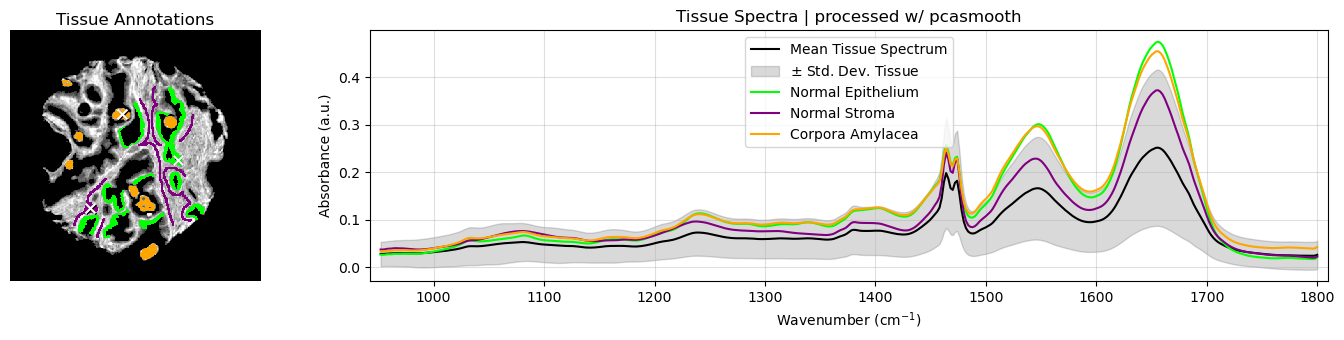

In [22]:
cm = "cm$^{-1}$"
fig,ax = plt.subplots(1,2,figsize=(14,3.5),width_ratios=(0.35,1))

ax[0].matshow(anno);  ax[0].set_axis_off()
ax[1].plot(processed_wavenumbers, meanspec_ir, c='k', label='Mean Tissue Spectrum')
ax[1].fill_between(processed_wavenumbers, meanspec_ir-stdspec_ir,meanspec_ir+stdspec_ir, color='k',alpha=0.15, label=r'$\pm$ Std. Dev. Tissue')
ax[1].set_xlim(xmin=processed_wavenumbers[0]-10,xmax=processed_wavenumbers[-1]+10,)
for i in range(3):
    ax[1].plot(processed_wavenumbers, ir[*locs_ir[i]], c=np.array(cols[i])/255.0,label = names[i])
    ax[0].scatter(locs_ir[i][1]+1,locs_ir[i][0]+1, color='black', marker='x',s=50)
    ax[0].scatter(locs_ir[i][1],locs_ir[i][0], color='white', marker='x',s=50)
ax[1].grid(alpha=0.4); ax[1].legend(loc='upper center')
ax[1].set_xlabel(f"Wavenumber ({cm})"); ax[1].set_ylabel("Absorbance (a.u.)")
ax[0].set_title("Tissue Annotations",y=0.99)
ax[1].set_title(f"Tissue Spectra | processed w/ {protocol_name}")

fig.tight_layout()
if not is_local:
    plt.savefig(f'./sample_processed.png')
    plt.close(fig)

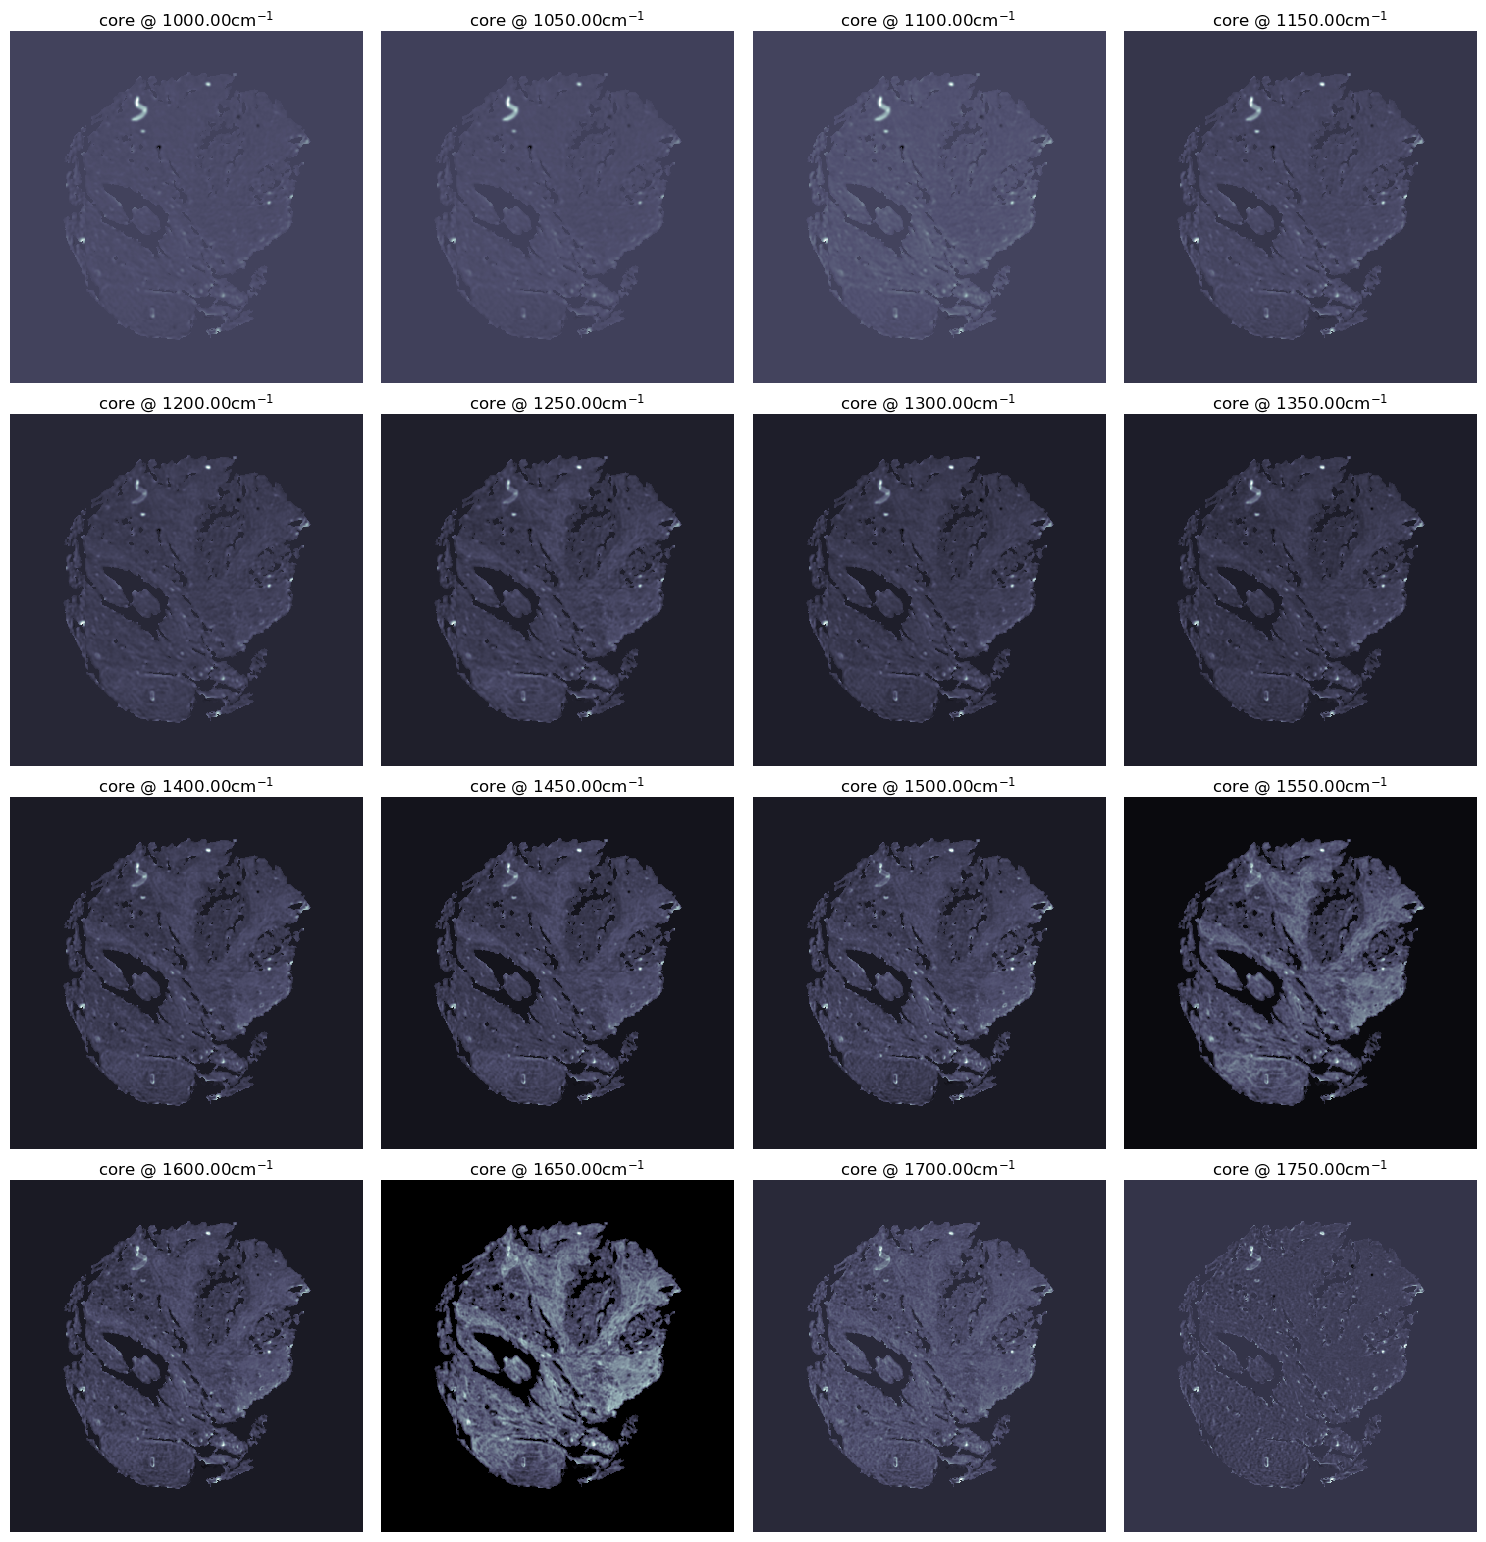

In [31]:
fig,ax = plt.subplots(4,4,figsize=(15,15.5)); ax = ax.flatten()
wvshows = np.arange(1000,1800,50)
for x in range(16):
    wvidx = np.argmin(np.abs(processed_wavenumbers-wvshows[x]))
    ax[x].matshow(ir[:,:,wvidx],cmap='bone');ax[x].set_axis_off()
    ax[x].set_title(f"core @ {processed_wavenumbers[wvidx]:.2f}{cm}",y=0.99)
fig.tight_layout()
if not is_local:
    plt.savefig(f'./sample_channels.png')
    plt.close(fig)

## Save Processing Results

In [ ]:
if not is_local:
    if os.path.isfile(f'results_processing.txt'):
        f = open(f'results_processing.txt', 'r')
        lines = f.readlines()
        f.close()
    else:
        lines = [x + ', \n' for x in ['protocol_name','cores_processed','total_time', 'mean_processing','std_processing']]

    # Process files
    lines[0] = lines[0].replace(f'\n', f'{protocol_name}, \n')
    lines[1] = lines[1].replace(f'\n', f'{len(master_nocl)+len(master_aus)}, \n')
    lines[2] = lines[2].replace(f'\n', f'{full_loop_time}, \n')
    lines[3] = lines[3].replace(f'\n', f'{mean_core_processing_time}, \n')
    lines[4] = lines[4].replace(f'\n', f'{std_core_processing_time}, \n')

    f = open(f'results_processing.txt', 'w')
    f.write(''.join(lines))
    f.close()